## PSA

### Bokeh

In [16]:
# Copyright 2026 Dylan. SPDX-License-Identifier: Apache-2.0
import numpy as np
import pandas as pd
from bokeh.models import HoverTool
from bokeh.palettes import Category20
from bokeh.plotting import figure, output_notebook, show

# Keep the original MT19937 sampling for comparable historical results.
rng = np.random.RandomState()

# Load the data
df = pd.read_csv(
    "/Users/doughnut/Downloads/Final_Updated_Microcosting_MLE.csv",
    usecols=["Test", "Category", "Stage", "LL", "MP", "UL", "Shape", "Scale"],
)
df_total_stage = df[(df["Category"] == "Total") & (df["Stage"] == "Total")]

# Generate gamma distribution samples
samples_total_stage = {
    row["Test"]: rng.gamma(row["Shape"], row["Scale"], 10000)
    for _, row in df_total_stage.iterrows()
}

# Create a Bokeh figure
p = figure(
    title="Gamma Distribution of Costs",
    x_axis_label="Cost (AUD)",
    y_axis_label="Count of Samples",
    sizing_mode="stretch_width",
    max_width=1000,
    plot_height=400,
)

# Get a color iterator from the palette
colors = iter(Category20[len(samples_total_stage)])

# Define x-axis range based on your data or a predetermined range
min_x, max_x = 0, 20000  # Update these values based on your data's range

# Add a histogram for each test
for test, data in samples_total_stage.items():
    hist, edges = np.histogram(data, bins=50, range=(min_x, max_x))
    p.quad(
        top=hist,
        bottom=0,
        left=edges[:-1],
        right=edges[1:],
        fill_color=next(colors),
        line_color="white",
        alpha=0.7,
        legend_label=test,
    )

# Customize the legend, tools, and x-axis range
p.legend.title = "Test"
p.legend.location = "top_right"
p.legend.click_policy = "mute"
p.x_range.start = min_x
p.x_range.end = max_x

hover = HoverTool(tooltips=[("Cost (AUD)", "@x"), ("Count", "@top")], mode="vline")
p.add_tools(hover)

# Display inline in Jupyter Notebook
output_notebook()

show(p)  # show the results

Loading BokehJS ...

### Plotly

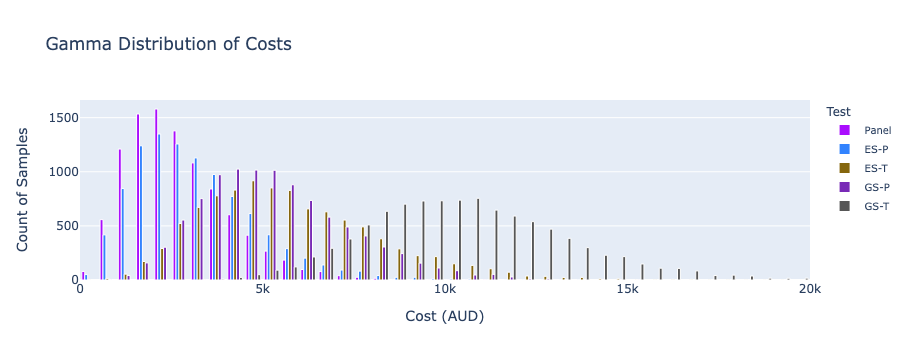

In [15]:
import numpy as np
import pandas as pd
import plotly.express as px  # for a larger color palette
import plotly.graph_objects as go

# Load the data
df = pd.read_csv(
    "/Users/doughnut/Downloads/Final_Updated_Microcosting_MLE.csv",
    usecols=["Test", "Category", "Stage", "LL", "MP", "UL", "Shape", "Scale"],
)
df_total_stage = df[(df["Category"] == "Total") & (df["Stage"] == "Total")]

# Generate gamma distribution samples
samples_total_stage = {
    row["Test"]: rng.gamma(row["Shape"], row["Scale"], 10000)
    for _, row in df_total_stage.iterrows()
}

# Create a Plotly figure
fig = go.Figure()

# Define a large color palette
color_palette = px.colors.qualitative.Alphabet  # This is a large color palette

# Define x-axis range based on your data or a predetermined range
min_x, max_x = 0, 20000  # Update these values based on your data's range

# Add a histogram for each test
for (test, data), color in zip(
    samples_total_stage.items(),
    color_palette,
    strict=False,
):
    fig.add_trace(
        go.Histogram(
            x=data,
            name=test,
            histnorm="",
            nbinsx=50,
            marker={"color": color, "line": {"color": "white", "width": 1}},
        ),
    )

# Update layout for better readability and set x-axis range
fig.update_layout(
    title_text="Gamma Distribution of Costs",
    xaxis={"title": "Cost (AUD)", "range": [min_x, max_x]},
    yaxis={"title": "Count of Samples"},
    bargap=0.2,  # space between bars
    legend={
        "title": "Test",
        "font": {"size": 10},
        "itemsizing": "constant",
    },  # Adjust legend properties
    hovermode="closest",
)

fig.show()

## DSA

### Bokeh

In [52]:
import numpy as np
import pandas as pd
from bokeh.layouts import gridplot
from bokeh.models import ColumnDataSource, HoverTool
from bokeh.plotting import figure, output_file, show

# Load the data
data = pd.read_csv(
    (
        "/Users/doughnut/Library/CloudStorage/OneDrive-TheUniversityofMelbourne/Phase"
        " 1 - Study 1 - Microcosting - Model "
        "1/MicrocostingDSA20230817(Actual).csv"
    ),
    usecols=["Test", "Category", "Scenario", "Value"],
)

# Define unique tests and categories for subplots
unique_tests = data["Test"].unique()
unique_categories = data["Category"].unique()

# Define colors for positive and negative differences
positive_color = "#87CEEB"  # Sky blue
negative_color = "#FFA07A"  # Light salmon


# Data processing and plot function for Bokeh
def bokeh_tornado_plot(
    data: pd.DataFrame,
    test: str,
    category: str,
    max_diff: float,
) -> figure:
    """Build a Bokeh tornado plot for the selected test and category."""
    subset = data[(data["Test"] == test) & (data["Category"] == category)]
    base_case_value = subset[subset["Scenario"].str.contains("base case")][
        "Value"
    ].to_numpy()[0]
    differences = subset["Value"] - base_case_value
    scenarios = subset["Scenario"]
    colors = [positive_color if x >= 0 else negative_color for x in differences]

    # Convert data to ColumnDataSource
    source = ColumnDataSource(
        data={"scenarios": scenarios, "differences": differences, "colors": colors},
    )

    # Create figure
    p = figure(
        y_range=scenarios,
        plot_width=300,
        plot_height=250,
        title=f"{test}\n{category}",
        toolbar_location=None,
    )
    p.hbar(
        y="scenarios",
        right="differences",
        height=0.5,
        source=source,
        color="colors",
    )

    # Add hover tool
    hover = HoverTool()
    hover.tooltips = [("Scenario", "@scenarios"), ("Difference", "@differences")]
    p.add_tools(hover)

    # Styling with smaller x-axis range
    p.x_range.start = -max_diff
    p.x_range.end = max_diff
    return p


# Create Bokeh figures and arrange them in a grid
plots = []
for _i, test in enumerate(unique_tests):
    for _j, category in enumerate(unique_categories):
        p = bokeh_tornado_plot(data, test, category, 2900)  # Adjusted max_diff
        plots.append(p)

# Arrange plots in a grid and show
grid = gridplot(plots, ncols=4)  # Set number of columns for the layout
output_file("/Users/doughnut/Downloads/DSA_Plotly.html")  # Update this path
show(grid)

### Plotly

In [54]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Load the data
data = pd.read_csv(
    (
        "/Users/doughnut/Library/CloudStorage/OneDrive-TheUniversityofMelbourne/Phase"
        " 1 - Study 1 - Microcosting - Model "
        "1/MicrocostingDSA20230817(Actual).csv"
    ),
    usecols=["Test", "Category", "Scenario", "Value"],
)

# Define unique tests and categories for subplots
unique_tests = data["Test"].unique()
unique_categories = data["Category"].unique()

# Define colors for positive and negative differences
positive_color = "#87CEEB"  # Sky blue
negative_color = "#FFA07A"  # Light salmon

# Create Plotly subplots (5x4 layout) with adjusted spacing
fig = make_subplots(
    rows=5,
    cols=4,
    subplot_titles=unique_categories.tolist(),
    horizontal_spacing=0.08,  # Increased horizontal spacing
    vertical_spacing=0.08,  # Increased vertical spacing
)

# Global maximum difference (adjust based on your data's needs)
global_max_diff = data["Value"].max() - data["Value"].min()


# Data processing and plot function for Plotly
def plotly_tornado_plot(
    fig: go.Figure,
    data: pd.DataFrame,
    selection: tuple[str, str],
    max_diff: float,
    subplot: tuple[int, int],
) -> None:
    """Add a tornado plot to the selected Plotly subplot."""
    test, category = selection
    row, col = subplot
    subset = data[(data["Test"] == test) & (data["Category"] == category)]
    base_case_value = subset[subset["Scenario"].str.contains("base case")][
        "Value"
    ].to_numpy()[0]
    differences = subset["Value"] - base_case_value
    scenarios = subset["Scenario"]

    # Splitting scenario text into two lines
    scenarios_split = [
        "<br>".join(s.split()) for s in scenarios
    ]  # Adjust splitting logic as needed

    # Adding each bar trace
    for scenario, difference in zip(scenarios_split, differences, strict=False):
        fig.add_trace(
            go.Bar(
                y=[scenario],
                x=[difference],
                orientation="h",
                marker_color=positive_color if difference >= 0 else negative_color,
            ),
            row=row,
            col=col,
        )

    # Update x-axis range
    fig.update_xaxes(range=[-max_diff, max_diff], row=row, col=col)


for i, test in enumerate(unique_tests):
    for j, category in enumerate(unique_categories):
        plotly_tornado_plot(
            fig,
            data,
            (test, category),
            global_max_diff,
            (i + 1, j + 1),
        )

# Update layout if needed and show the plot (5x4 layout)
fig.update_layout(
    height=1000,
    width=1200,
    title_text="Tornado Charts",
    showlegend=False,
)

# Update layout if needed and show the plot (5x4 layout)
fig.write_html("/Users/doughnut/Downloads/PSA_Plotly.html")  # Update this path